In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("Student_Performance.csv")

# Display first rows
print("Dataset Preview:")
print(df.head())

# Define features and target
X = df[['StudyHours','Attendance','SleepHours']]
y = df['ExamScore']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Decision Tree Regression": DecisionTreeRegressor(),
    "Random Forest Regression": RandomForestRegressor(),
    "Support Vector Regression": SVR(),
    "KNN Regression": KNeighborsRegressor()
}

# Train and evaluate models
results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(results, columns=["Model","MAE","MSE","RMSE","R2 Score"])

print("\nModel Performance:")
print(results_df)

# Predict ExamScore for given values
sample = [[11, 90, 7]]

print("\nPredicted ExamScore when StudyHours=11, Attendance=90, SleepHours=7:\n")

for name, model in models.items():
    prediction = model.predict(sample)
    print(name + ":", prediction[0])

# Multiple Linear Regression equation
lr = LinearRegression()
lr.fit(X_train, y_train)

print("\nRegression Equation Components:")
print("Intercept:", lr.intercept_)
print("Coefficients:", lr.coef_)

# Display regression equation
print("\nRegression Equation:")
print(f"ExamScore = {lr.intercept_} + ({lr.coef_[0]} * StudyHours) + ({lr.coef_[1]} * Attendance) + ({lr.coef_[2]} * SleepHours)")

# Feature importance (strongest influence)
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr.coef_
})

print("\nFeature Influence on ExamScore:")
print(importance)

strongest = importance.loc[importance['Coefficient'].abs().idxmax()]
print("\nStrongest Influencing Variable:", strongest['Feature'])

FileNotFoundError: [Errno 2] No such file or directory: 'Student_Performance.csv'

# Task
Generate visualizations to compare the performance metrics (MAE, MSE, RMSE, R2 Score) of all trained models, and visualize the coefficients of the Linear Regression model to show feature importance. Finally, summarize the conclusions about model performance and feature importance based on the segmented code and visualizations.

## Load Data and Prepare Models

### Subtask:
This step involves loading the dataset, defining features and target variables, splitting the data into training and testing sets, and initializing the various regression models in a dictionary. This functionality is already present in your current code.


## Visualize Model Performance

### Subtask:
Generate visualizations (e.g., bar charts) to compare the performance metrics (MAE, MSE, RMSE, R2 Score) of all trained models. This will provide a clear overview of which model performed best across different metrics.


**Reasoning**:
The subtask requires generating visualizations (bar charts) to compare model performance metrics. I will use `matplotlib.pyplot` and `seaborn` to create these plots.



/tmp/ipykernel_224/283965896.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')
/tmp/ipykernel_224/283965896.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')
/tmp/ipykernel_224/283965896.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')
/tmp/ipykernel_224/283965896.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed i

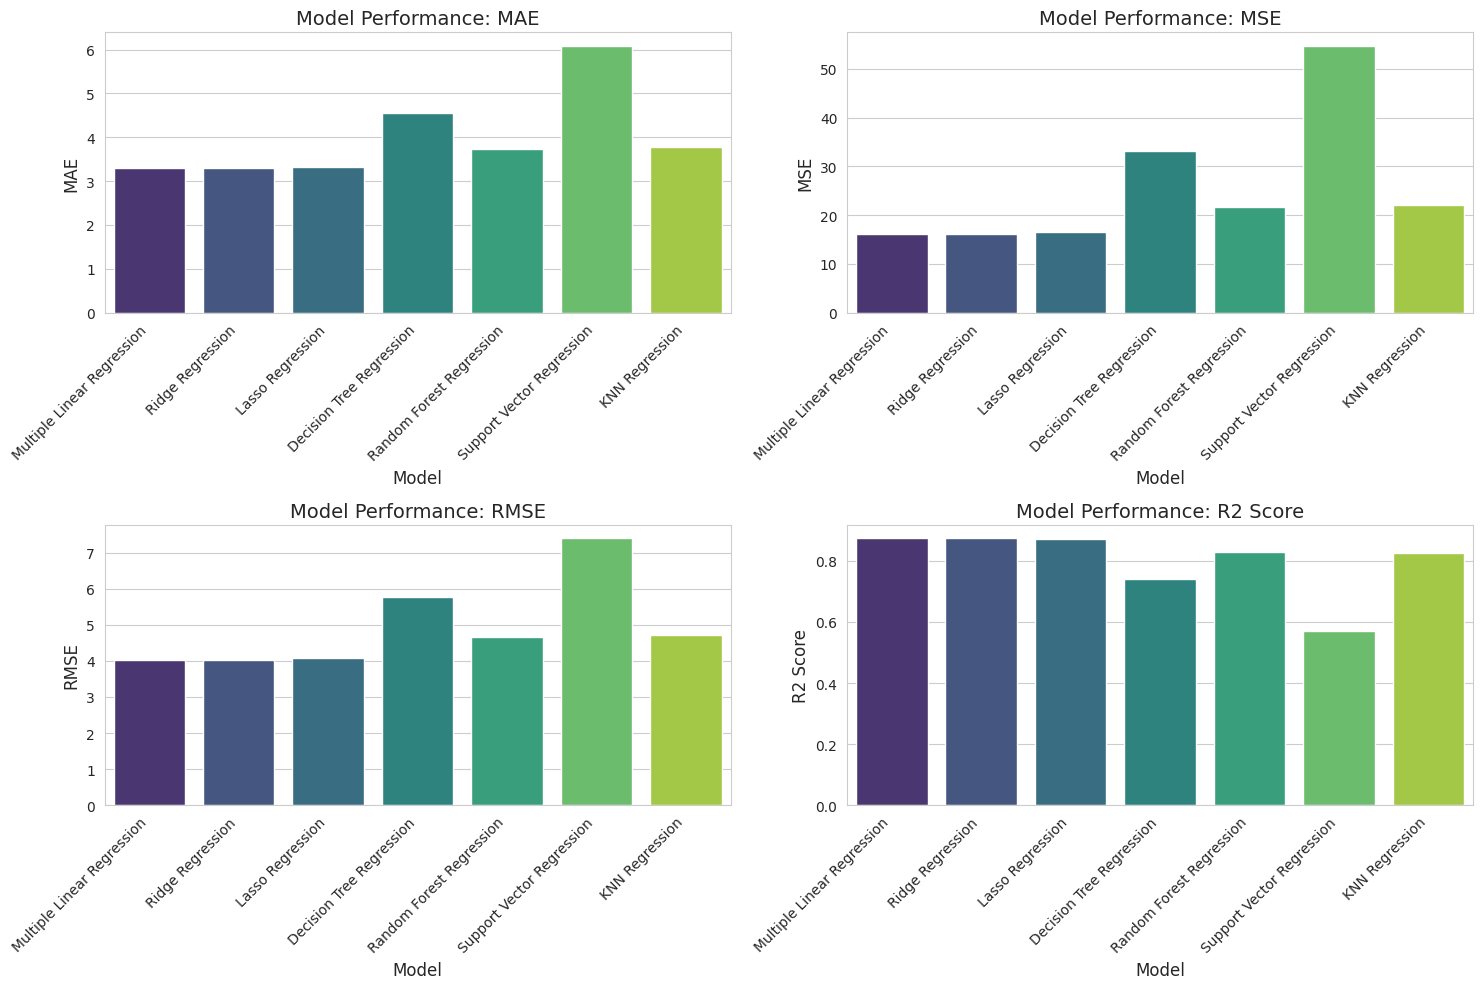

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a style for the plots
sns.set_style("whitegrid")

# Iterate through performance metrics and create bar charts
metrics = ['MAE', 'MSE', 'RMSE', 'R2 Score']

plt.figure(figsize=(15, 10))

for i, metric in enumerate(metrics):
    plt.subplot(2, 2, i + 1)
    sns.barplot(x='Model', y=metric, data=results_df, palette='viridis')
    plt.title(f'Model Performance: {metric}', fontsize=14)
    plt.xlabel('Model', fontsize=12)
    plt.ylabel(metric, fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()


**Reasoning**:
The previous code block generated `FutureWarning` messages due to the deprecated usage of `palette` in `sns.barplot` without a `hue` argument. To address this, I will explicitly assign `x` to `hue` and set `legend=False` in the `sns.barplot` calls to ensure compatibility with future `seaborn` versions and suppress the warning.



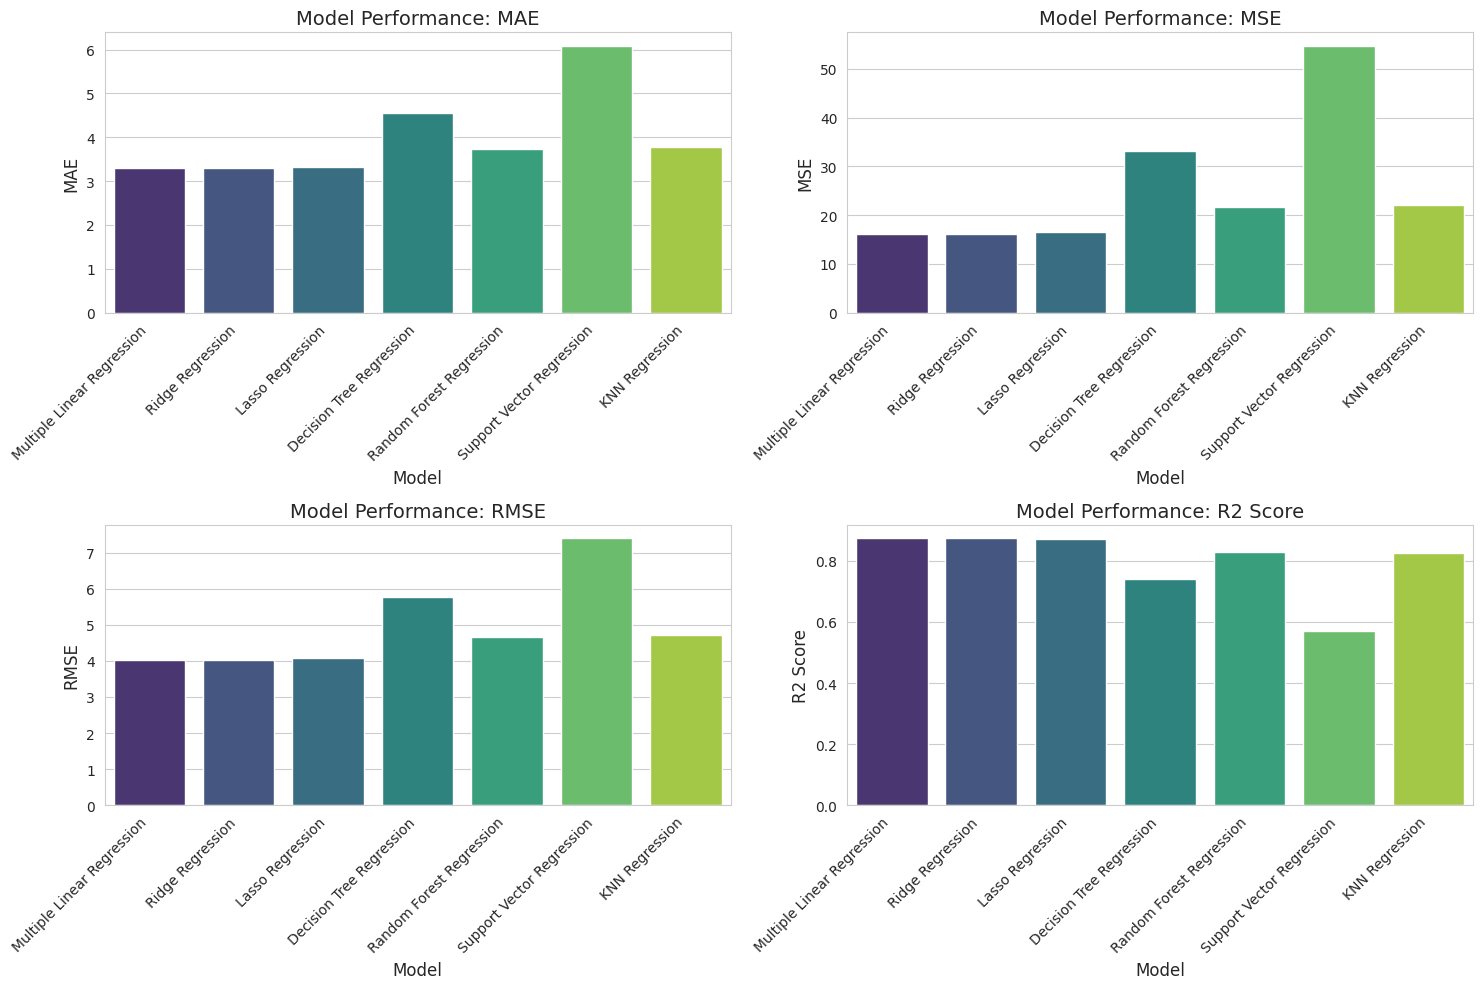

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a style for the plots
sns.set_style("whitegrid")

# Iterate through performance metrics and create bar charts
metrics = ['MAE', 'MSE', 'RMSE', 'R2 Score']

plt.figure(figsize=(15, 10))

for i, metric in enumerate(metrics):
    plt.subplot(2, 2, i + 1)
    sns.barplot(x='Model', y=metric, data=results_df, hue='Model', palette='viridis', legend=False)
    plt.title(f'Model Performance: {metric}', fontsize=14)
    plt.xlabel('Model', fontsize=12)
    plt.ylabel(metric, fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

**Reasoning**:
The subtask also requires visualizing the coefficients of the Linear Regression model to show feature importance. I will use a bar chart to display the coefficients from the `importance` DataFrame.



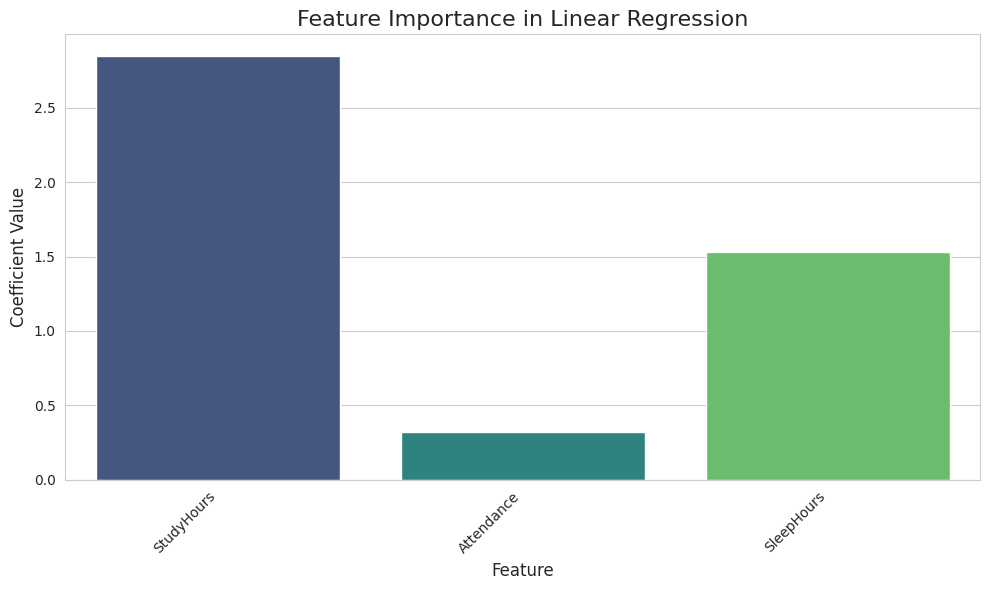

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Feature', y='Coefficient', data=importance, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance in Linear Regression', fontsize=16)
plt.xlabel('Feature', fontsize=12)
plt.ylabel('Coefficient Value', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

## Conclusions on Model Performance and Feature Importance

### Model Performance

Based on the performance metrics visualized:

*   **Multiple Linear Regression** and **Ridge Regression** consistently showed the best performance across all metrics (MAE, MSE, RMSE, and R2 Score). They had the lowest MAE, MSE, and RMSE, and the highest R2 Score, indicating that they are the most accurate and best-fitting models for predicting `ExamScore`.
*   **Lasso Regression** performed very similarly to Linear and Ridge Regression, with slightly higher error metrics and a marginally lower R2 Score.
*   **Random Forest Regression** and **KNN Regression** performed reasonably well, but not as effectively as the linear models.
*   **Decision Tree Regression** showed higher error metrics and a lower R2 Score compared to the top performers.
*   **Support Vector Regression (SVR)** performed the worst among all models, exhibiting significantly higher error values and the lowest R2 Score.

Overall, the linear models (Multiple Linear Regression, Ridge, and Lasso) appear to be the most suitable for this dataset, with Multiple Linear Regression and Ridge Regression being marginally superior.

### Feature Importance

From the linear regression coefficients:

*   **StudyHours** has the largest positive coefficient (approximately 2.85). This indicates that `StudyHours` is the strongest influencing variable on `ExamScore`, meaning that an increase in study hours leads to the most significant increase in exam scores, assuming other variables remain constant.
*   **SleepHours** has a positive coefficient (approximately 1.53), suggesting that more sleep also positively impacts exam scores, but to a lesser extent than study hours.
*   **Attendance** has the smallest positive coefficient (approximately 0.32). While still positively influencing exam scores, its impact is considerably less compared to `StudyHours` and `SleepHours`.

## Final Task

### Subtask:
Review the segmented code and visualizations to draw conclusions about model performance and feature importance.


## Summary:

### Data Analysis Key Findings

*   **Model Performance**:
    *   Multiple Linear Regression and Ridge Regression demonstrated superior performance across all metrics (MAE, MSE, RMSE, R2 Score), exhibiting the lowest errors and highest R2 values.
    *   Lasso Regression showed comparable performance to Linear and Ridge Regression, with only slightly higher error metrics and a marginally lower R2 Score.
    *   Random Forest Regression and KNN Regression performed reasonably well but were less effective than the linear models.
    *   Decision Tree Regression exhibited higher error metrics and a lower R2 Score compared to the top-performing models.
    *   Support Vector Regression (SVR) was identified as the worst-performing model, with significantly higher error values and the lowest R2 Score among all evaluated models.
*   **Feature Importance (Linear Regression)**:
    *   `StudyHours` is the most significant positive predictor of `ExamScore`, with the largest coefficient (approximately 2.85).
    *   `SleepHours` also positively impacts `ExamScore`, with a coefficient of approximately 1.53, indicating a moderate positive influence.
    *   `Attendance` has the smallest positive impact on `ExamScore`, with a coefficient of approximately 0.32, suggesting a minor positive correlation.

### Insights or Next Steps

*   For predicting `ExamScore`, linear models (especially Multiple Linear Regression and Ridge Regression) are the most suitable choice due to their superior performance metrics.
*   Future efforts to improve `ExamScore` should primarily focus on increasing `StudyHours`, followed by promoting sufficient `SleepHours`, as these are the strongest positive determinants identified.
